# NSL-KDD Intrusion Detection — Logistic Regression, KNN, and Decision Tree

**MSc Practical Machine Learning project**

## Objective
Classify network connections as **normal** or **attack** using the NSL-KDD dataset. Compare three requested model families: Logistic Regression, K-Nearest Neighbors (KNN), and Decision Tree.

## Preserving the existing workflow
This notebook carries forward the feature engineering choices from the previous notebook:
- Use the 41 named NSL-KDD connection features and `class` target.
- Remove constant columns and rows with missing values, as in the earlier workflow.
- Remove the same highly correlated features: `num_root`, `srv_serror_rate`, `srv_rerror_rate`, `dst_host_srv_serror_rate`, `dst_host_serror_rate`, `dst_host_rerror_rate`, `dst_host_srv_rerror_rate`, and `dst_host_same_srv_rate`.
- Map `protocol_type` and `flag` using the original mappings.
- Drop `service`, as in the previous version.
- Keep SMOTE as the primary resampling experiment.

## Two necessary correctness fixes
1. The dataset is split **before** fitting `MinMaxScaler`, to avoid test-set information leaking into preprocessing.
2. SMOTE is applied **only to training data**, never to validation or test data.

The target is converted to binary: `normal` → 0 and all recognized attack labels → 1. This is the first intrusion-detection task; identifying individual attack categories can be a later multiclass extension. The notebook will inspect the actual labels and stop with a clear error if the expected target column/data layout is not found.

In [24]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import sys
print("Python version:", sys.version)
print("Python path:", sys.executable)
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "seaborn==0.13.2"
])

subprocess.check_call([

    sys.executable,

    "-m",

    "pip",

    "install",

    "imbalanced-learn"

])

import seaborn as sns
print("Seaborn version:", sns.__version__)

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, balanced_accuracy_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
DATA_PATH = "nsl_kdd.csv"
pd.set_option("display.max_columns", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

print("Working directory:", os.getcwd())
print("Dataset path:", os.path.abspath(DATA_PATH))

Python version: 3.12.15 (main, Sep 30 2026, 22:04:19) [Clang 21.0.0 (clang-2100.3.34.2)]
Python path: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects/.venv/bin/python



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Seaborn version: 0.13.2
Working directory: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects
Dataset path: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects/nsl_kdd.csv



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## 1. Load and validate the dataset

The original notebook defines the standard 41 NSL-KDD feature names and then `class`. This cell supports either a headerless NSL-KDD-style CSV or a CSV with column headers. If your file has a different schema, it reports the columns so they can be checked instead of silently assigning incorrect names.

In [25]:
feature_text = """duration,
protocol_type,
service,
flag,
src_bytes,
dst_bytes,
land,
wrong_fragment,
urgent,
hot,
num_failed_logins,
logged_in,
num_compromised,
root_shell,
su_attempted,
num_root,
num_file_creations,
num_shells,
num_access_files,
num_outbound_cmds,
is_host_login,
is_guest_login,
count,
srv_count,
serror_rate,
srv_serror_rate,
rerror_rate,
srv_rerror_rate,
same_srv_rate,
diff_srv_rate,
srv_diff_host_rate,
dst_host_count,
dst_host_srv_count,
dst_host_same_srv_rate,
dst_host_diff_srv_rate,
dst_host_same_src_port_rate,
dst_host_srv_diff_host_rate,
dst_host_serror_rate,
dst_host_srv_serror_rate,
dst_host_rerror_rate,
dst_host_srv_rerror_rate"""
feature_columns = [c.strip() for c in feature_text.split(",") if c.strip()]
expected_columns = feature_columns + ["class"]

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH!r}. Put nsl_kdd.csv in the same folder as this notebook "
        "or update DATA_PATH."
    )

# First read normally. If the expected target header is not present and there are 42 columns,
# treat the file as headerless and apply the standard NSL-KDD column names.
raw = pd.read_csv(DATA_PATH, low_memory=False)
normalised_names = [str(c).strip().lower().rstrip(".") for c in raw.columns]
if "class" not in normalised_names and raw.shape[1] == 42:
    raw = pd.read_csv(DATA_PATH, header=None, names=expected_columns, low_memory=False)
    print("Loaded as a headerless 42-column NSL-KDD file.")
else:
    raw.columns = [str(c).strip().lower().rstrip(".") for c in raw.columns]
    if "class" not in raw.columns and raw.shape[1] == 42:
        raw.columns = expected_columns
    print("Loaded CSV with its detected header.")

# Standardize common target-column naming variations.
if "class" not in raw.columns:
    target_candidates = [c for c in raw.columns if c in {"label", "target", "attack"}]
    if target_candidates:
        raw = raw.rename(columns={target_candidates[0]: "class"})

print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head())

Loaded as a headerless 42-column NSL-KDD file.
Shape: (125973, 42)
Columns: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'class']


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


## 2. Data inspection and target definition

We preserve the prior cleaning approach: remove fully missing columns, remove rows with missing values, and remove constant columns. The target is then mapped to a binary intrusion-detection target. Any label other than a recognized normal label is treated as an attack, which is appropriate for binary IDS; the observed labels are printed for verification.

In [26]:
if "class" not in raw.columns:
    raise ValueError("Target column 'class' was not found. Check the CSV header and column layout.")

df = raw.copy()
df.columns = [str(c).strip().lower().rstrip(".") for c in df.columns]

print("Original shape:", df.shape)
print("Missing values (top):")
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

# Preserve the original notebook's cleaning choice: drop columns containing missing values,
# then retain columns with more than one unique value.
# (This is intentionally column-wise, matching the earlier code's df.dropna('columns').)
#df = df.dropna(axis="columns", how="any")
df = df.loc[:, df.nunique(dropna=False) > 1].copy()

# Normalise string labels such as 'normal.' and 'neptune.'.
df["class"] = df["class"].astype(str).str.strip().str.lower().str.rstrip(".")
print("Original class labels:")
display(df["class"].value_counts().to_frame("count"))

normal_labels = {"normal"}
df["target_binary"] = np.where(df["class"].isin(normal_labels), 0, 1).astype(int)
print("Binary target distribution (0=normal, 1=attack):")
display(df["target_binary"].value_counts().rename(index={0:"Normal (0)", 1:"Attack (1)"}).to_frame("count"))
print("Rows after missing/constant-column cleaning:", df.shape[0])

Original shape: (125973, 42)
Missing values (top):


,missing_count
duration,0
dst_host_count,0
srv_count,0
serror_rate,0
srv_serror_rate,0
rerror_rate,0
srv_rerror_rate,0
same_srv_rate,0
diff_srv_rate,0
srv_diff_host_rate,0


Original class labels:


,count
class,
normal,67343
anomaly,58630


Binary target distribution (0=normal, 1=attack):


,count
target_binary,
Normal (0),67343
Attack (1),58630


Rows after missing/constant-column cleaning: 125973


## 3. Exploratory analysis

The correlation heatmap uses numeric columns only, so categorical strings and the target do not cause a correlation error. Correlation is used as a diagnostic; the specified feature removals from the original notebook are retained below.

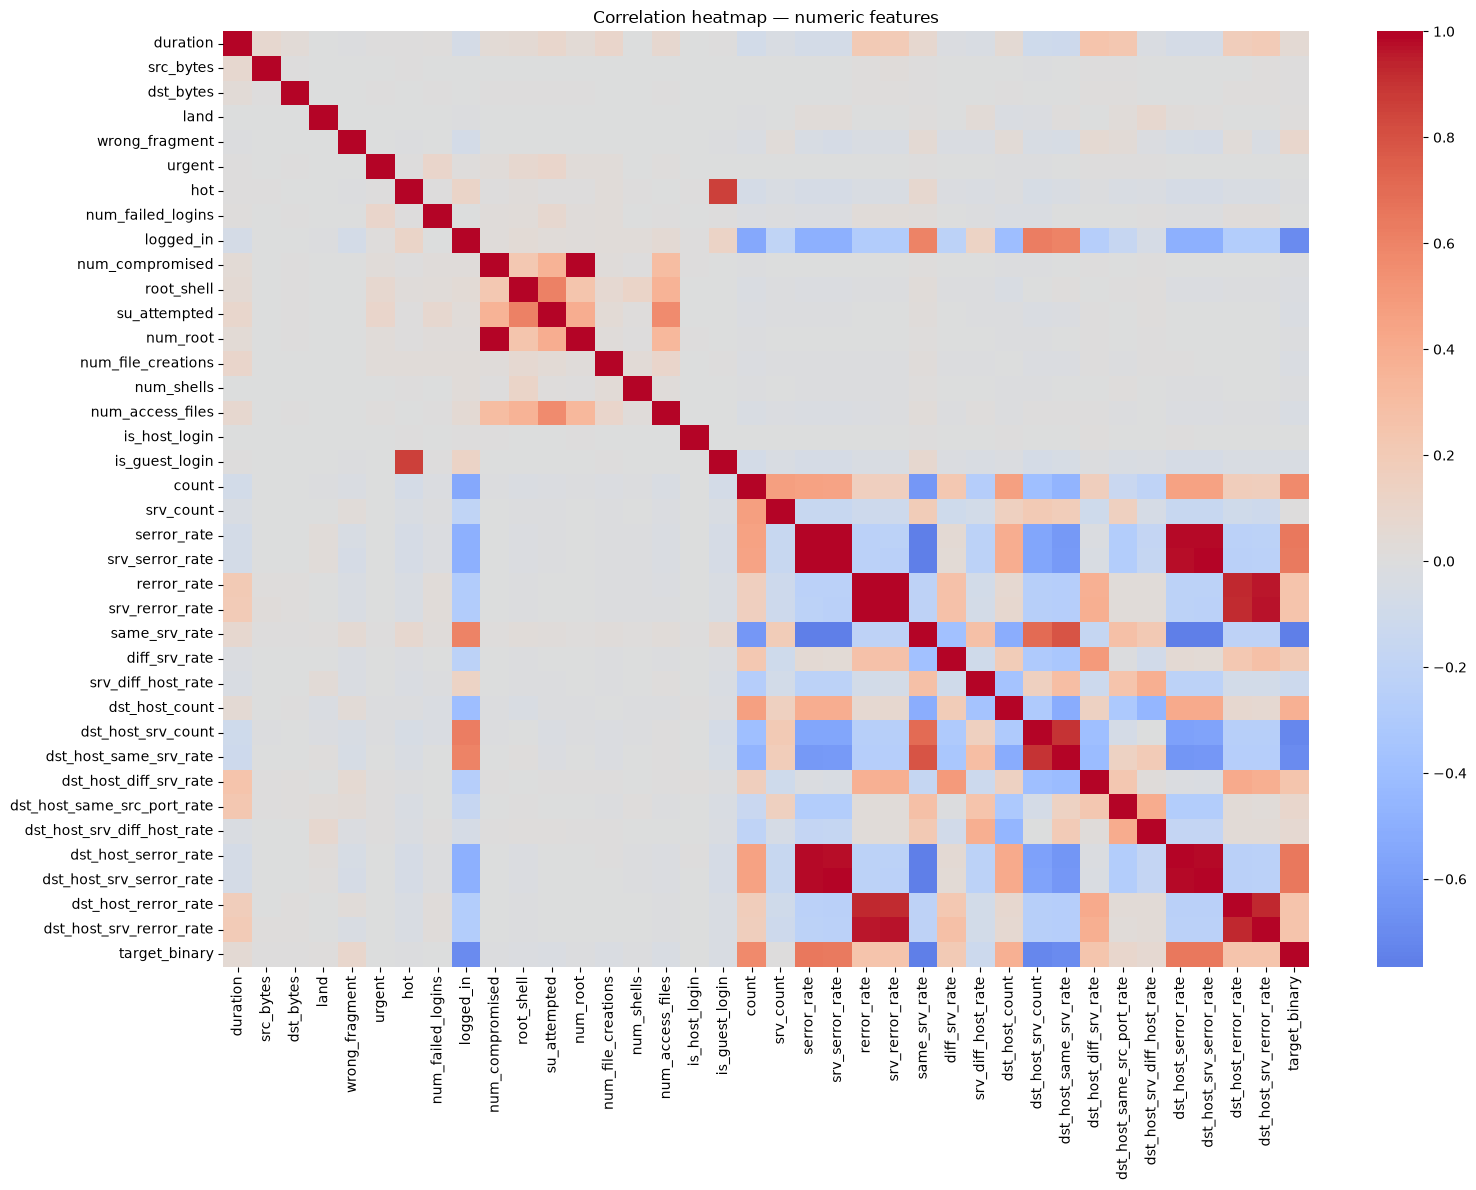

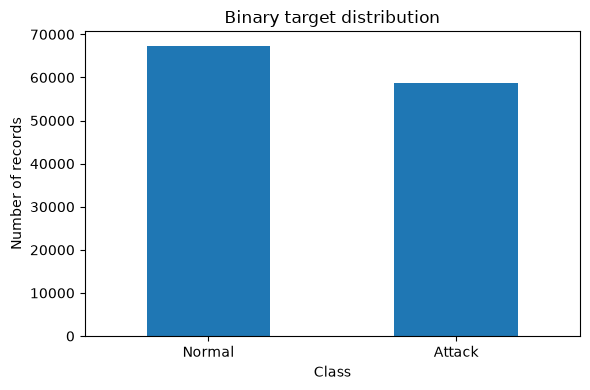

In [27]:
numeric_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(16, 12))
sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Correlation heatmap — numeric features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
df["target_binary"].map({0:"Normal", 1:"Attack"}).value_counts().plot(kind="bar")
plt.title("Binary target distribution")
plt.ylabel("Number of records")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Feature engineering — retain the previous choices

The following changes intentionally match the earlier notebook. Correlated features are removed using the same list; `protocol_type` and `flag` use the same numeric mappings; `service` is dropped. We add no new feature selection in this version.

A check is included so that a feature absent from a variant of the dataset does not cause an obscure error.

In [28]:
# Same correlated-feature removals as the original notebook.
correlated_to_drop = [
    "num_root",
    "srv_serror_rate",
    "srv_rerror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "dst_host_same_srv_rate",
]
present_to_drop = [c for c in correlated_to_drop if c in df.columns]
df = df.drop(columns=present_to_drop)
print("Removed correlated features:", present_to_drop)

# Same protocol_type mapping as the original notebook.
if "protocol_type" in df.columns:
    pmap = {"icmp": 0, "tcp": 1, "udp": 2}
    df["protocol_type"] = df["protocol_type"].astype(str).str.strip().str.lower().map(pmap)

# Same flag mapping as the original notebook.
if "flag" in df.columns:
    fmap = {
        "SF": 0, "S0": 1, "REJ": 2, "RSTR": 3, "RSTO": 4,
        "SH": 5, "S1": 6, "S2": 7, "RSTOS0": 8, "S3": 9, "OTH": 10
    }
    df["flag"] = df["flag"].astype(str).str.strip().str.upper().map(fmap)

# Same service removal as the original notebook.
if "service" in df.columns:
    df = df.drop(columns=["service"])
    print("Dropped service feature, preserving the previous workflow.")

# Remove original string target and use the binary target.
X = df.drop(columns=["class", "target_binary"], errors="ignore").copy()
y = df["target_binary"].copy()

# Ensure all features are numeric after the original mappings.
non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    raise ValueError(
        "These features are still non-numeric after the preserved mappings: "
        f"{non_numeric}. Please inspect their values before training."
    )

# Mappings may create NaNs if unexpected category values occur; show them explicitly.
unmapped_counts = X.isna().sum()
unmapped_counts = unmapped_counts[unmapped_counts > 0]
if len(unmapped_counts):
    print("Missing/unmapped feature values that will be imputed within the training pipeline:")
    display(unmapped_counts.to_frame("count"))

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Feature columns:", X.columns.tolist())

Removed correlated features: ['num_root', 'srv_serror_rate', 'srv_rerror_rate', 'dst_host_srv_serror_rate', 'dst_host_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'dst_host_same_srv_rate']
Dropped service feature, preserving the previous workflow.
Feature matrix: (125973, 31)
Target vector: (125973,)
Feature columns: ['duration', 'protocol_type', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate']


## 5. Train, validation, and test split

The original workflow used a random 67%/33% train/test split. Here we use a stratified 70%/15%/15% train/validation/test split to support fair model selection. This is a methodological correction rather than a feature-engineering change.

**Critical correction:** the scaler is fitted only on training data. The validation and test partitions are never used to fit the scaler or to generate synthetic SMOTE examples.

In [29]:
# 70% train, 15% validation, 15% test; stratify to preserve binary class proportions.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15 / 0.85,
    random_state=RANDOM_STATE, stratify=y_trainval
)

print("Rows — train/validation/test:", len(X_train), len(X_val), len(X_test))
split_summary = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).fillna(0).rename(index={0:"Normal (0)", 1:"Attack (1)"})
display((split_summary * 100).round(2).rename_axis("Class").rename(columns=lambda c: f"{c} (%)"))

# Fit MinMaxScaler on training data only, preserving the prior scaling method.
imputer = SimpleImputer(strategy="median")
scaler = MinMaxScaler()
X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Scaled matrix shapes:", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

Rows — train/validation/test: 88181 18896 18896


,train (%),validation (%),test (%)
Class,,,
Normal (0),53.46,53.46,53.46
Attack (1),46.54,46.54,46.54


Scaled matrix shapes: (88181, 31) (18896, 31) (18896, 31)


## 6. SMOTE — retained as requested

SMOTE is applied only to the scaled training partition. Validation and test data keep their original class distribution so that evaluation reflects realistic held-out data.

If the minority class has too few examples for the default five neighbours, the code automatically selects a valid `k_neighbors`. If SMOTE cannot be applied, the cell raises a clear error rather than silently continuing with an unbalanced or incorrectly prepared dataset.

In [30]:
from collections import Counter

print("Training class counts before SMOTE:", Counter(y_train))
minority_count = int(y_train.value_counts().min())
if minority_count < 2:
    raise ValueError("SMOTE requires at least two examples in the minority class.")

smote_k = min(5, minority_count - 1)
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Training class counts after SMOTE:", Counter(y_train_smote))
print("Validation counts (unchanged):", Counter(y_val))
print("Test counts (unchanged):", Counter(y_test))

Training class counts before SMOTE: Counter({0: 47140, 1: 41041})
Training class counts after SMOTE: Counter({0: 47140, 1: 47140})
Validation counts (unchanged): Counter({0: 10102, 1: 8794})
Test counts (unchanged): Counter({0: 10101, 1: 8795})


## 7. Evaluation helpers

Accuracy is included, but it is not the only metric. For intrusion detection, attack recall (detection rate), precision, F1, balanced accuracy, confusion matrices, and ROC-AUC are also important. The positive class is **Attack (1)**.

In [31]:
def evaluate_classifier(model, X_eval, y_eval, split_name="Validation"):
    pred = model.predict(X_eval)
    result = {
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (attack)": precision_score(y_eval, pred, zero_division=0),
        "Recall / Detection rate (attack)": recall_score(y_eval, pred, zero_division=0),
        "F1 (attack)": f1_score(y_eval, pred, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_eval, pred),
    }
    if hasattr(model, "predict_proba"):
        try:
            scores = model.predict_proba(X_eval)[:, 1]
            result["ROC-AUC"] = roc_auc_score(y_eval, scores)
            result["PR-AUC (average precision)"] = average_precision_score(y_eval, scores)
        except Exception:
            result["ROC-AUC"] = np.nan
            result["PR-AUC (average precision)"] = np.nan
    else:
        result["ROC-AUC"] = np.nan
        result["PR-AUC (average precision)"] = np.nan
    return result, pred

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 8. Model 1 — Logistic Regression

Logistic Regression is the linear classification baseline. We keep the model type requested and tune regularisation strength using validation performance. The model is trained on the SMOTE-resampled training data.

In [32]:
lr_results = []
lr_models = {}
for C in [0.1, 1.0, 10.0]:
    model = LogisticRegression(
        C=C, max_iter=2000, class_weight=None, random_state=RANDOM_STATE
    )
    t0 = time.perf_counter()
    model.fit(X_train_smote, y_train_smote)
    train_seconds = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(X_val_scaled)
    predict_seconds = time.perf_counter() - t0
    res, _ = evaluate_classifier(model, X_val_scaled, y_val, "Validation")
    res.update({"Model": "Logistic Regression", "C": C,
                "Training time (s)": train_seconds, "Prediction time (s)": predict_seconds})
    lr_results.append(res)
    lr_models[C] = model

lr_table = pd.DataFrame(lr_results).sort_values(["F1 (attack)", "Recall / Detection rate (attack)"], ascending=False)
display(lr_table.round(4))
best_lr_C = float(lr_table.iloc[0]["C"])
best_lr = lr_models[best_lr_C]
print("Selected Logistic Regression C:", best_lr_C)

,Split,Accuracy,Precision (attack),Recall / Detection rate (attack),F1 (attack),Balanced accuracy,ROC-AUC,PR-AUC (average precision),Model,C,Training time (s),Prediction time (s)
0,Validation,0.9533,0.9554,0.9437,0.9495,0.9527,0.9883,0.9887,Logistic Regression,0.1,0.2201,0.0019
2,Validation,0.9528,0.9527,0.9455,0.9491,0.9523,0.9894,0.9889,Logistic Regression,10.0,0.4126,0.0004
1,Validation,0.9526,0.9544,0.9433,0.9488,0.9520,0.9889,0.9889,Logistic Regression,1.0,0.3058,0.0014


Selected Logistic Regression C: 0.1


## 9. Model 2 — K-Nearest Neighbors (KNN)

KNN is distance-based, so the MinMax scaling is important. We test a small set of neighbour counts and distance-weighting options. If this dataset is very large, KNN prediction may be slower; timing is reported.

In [33]:
knn_results = []
knn_models = {}
for k in [3, 5, 7, 11]:
    for weights in ["uniform", "distance"]:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights, n_jobs=-1)
        t0 = time.perf_counter()
        model.fit(X_train_smote, y_train_smote)
        train_seconds = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred = model.predict(X_val_scaled)
        predict_seconds = time.perf_counter() - t0
        res, _ = evaluate_classifier(model, X_val_scaled, y_val, "Validation")
        res.update({"Model": "KNN", "n_neighbors": k, "weights": weights,
                    "Training time (s)": train_seconds, "Prediction time (s)": predict_seconds})
        knn_results.append(res)
        knn_models[(k, weights)] = model

knn_table = pd.DataFrame(knn_results).sort_values(["F1 (attack)", "Recall / Detection rate (attack)"], ascending=False)
display(knn_table.round(4))
best_knn_params = (int(knn_table.iloc[0]["n_neighbors"]), str(knn_table.iloc[0]["weights"]))
best_knn = knn_models[best_knn_params]
print("Selected KNN settings:", best_knn_params)

,Split,Accuracy,Precision (attack),Recall / Detection rate (attack),F1 (attack),Balanced accuracy,ROC-AUC,PR-AUC (average precision),Model,n_neighbors,weights,Training time (s),Prediction time (s)
1,Validation,0.9944,0.9939,0.9941,0.9940,0.9944,0.9973,0.9959,KNN,3,distance,0.0033,1.0822
5,Validation,0.9942,0.9942,0.9934,0.9938,0.9942,0.9989,0.9983,KNN,7,distance,0.0033,0.9640
3,Validation,0.9942,0.9939,0.9936,0.9937,0.9941,0.9981,0.9972,KNN,5,distance,0.0040,0.9767
0,Validation,0.9936,0.9928,0.9935,0.9932,0.9936,0.9974,0.9959,KNN,3,uniform,0.0097,1.1003
7,Validation,0.9932,0.9931,0.9924,0.9927,0.9932,0.9990,0.9987,KNN,11,distance,0.0033,0.9636
2,Validation,0.9923,0.9927,0.9907,0.9917,0.9922,0.9982,0.9972,KNN,5,uniform,0.0035,1.0286
4,Validation,0.9919,0.9924,0.9902,0.9913,0.9918,0.9989,0.9983,KNN,7,uniform,0.0055,0.9614
6,Validation,0.9910,0.9913,0.9892,0.9903,0.9908,0.9990,0.9988,KNN,11,uniform,0.0033,0.9672


Selected KNN settings: (3, 'distance')


## 10. Model 3 — Decision Tree

Decision Trees can learn nonlinear rules and do not require feature scaling in principle. We keep the same scaled inputs here to maintain a consistent comparison with the other models, and test a compact set of depth/leaf settings.

In [34]:
dt_results = []
dt_models = {}
for max_depth in [None, 10, 20, 30]:
    for min_samples_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            class_weight=None,
        )
        t0 = time.perf_counter()
        model.fit(X_train_smote, y_train_smote)
        train_seconds = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred = model.predict(X_val_scaled)
        predict_seconds = time.perf_counter() - t0
        res, _ = evaluate_classifier(model, X_val_scaled, y_val, "Validation")
        res.update({"Model": "Decision Tree", "max_depth": str(max_depth),
                    "min_samples_leaf": min_samples_leaf,
                    "Training time (s)": train_seconds, "Prediction time (s)": predict_seconds})
        dt_results.append(res)
        dt_models[(max_depth, min_samples_leaf)] = model

dt_table = pd.DataFrame(dt_results).sort_values(["F1 (attack)", "Recall / Detection rate (attack)"], ascending=False)
display(dt_table.round(4))
best_dt_params = (dt_table.iloc[0]["max_depth"], int(dt_table.iloc[0]["min_samples_leaf"]))
best_dt_depth = None if best_dt_params[0] == "None" else int(best_dt_params[0])
best_dt = dt_models[(best_dt_depth, best_dt_params[1])]
print("Selected Decision Tree settings:", (best_dt_depth, best_dt_params[1]))

,Split,Accuracy,Precision (attack),Recall / Detection rate (attack),F1 (attack),Balanced accuracy,ROC-AUC,PR-AUC (average precision),Model,max_depth,min_samples_leaf,Training time (s),Prediction time (s)
0,Validation,0.9952,0.9950,0.9948,0.9949,0.9952,0.9952,0.9922,Decision Tree,None,1,0.3505,0.0012
9,Validation,0.9952,0.9950,0.9948,0.9949,0.9952,0.9952,0.9922,Decision Tree,30,1,0.2788,0.0011
6,Validation,0.9952,0.9949,0.9948,0.9948,0.9952,0.9959,0.9930,Decision Tree,20,1,0.2752,0.0011
7,Validation,0.9947,0.9956,0.9931,0.9943,0.9946,0.9976,0.9964,Decision Tree,20,5,0.2750,0.0011
1,Validation,0.9944,0.9952,0.9928,0.9940,0.9943,0.9973,0.9959,Decision Tree,None,5,0.2737,0.0011
10,Validation,0.9944,0.9952,0.9928,0.9940,0.9943,0.9973,0.9959,Decision Tree,30,5,0.2729,0.0011
2,Validation,0.9935,0.9936,0.9924,0.9930,0.9934,0.9989,0.9984,Decision Tree,None,10,0.2660,0.0011
8,Validation,0.9935,0.9936,0.9924,0.9930,0.9934,0.9989,0.9984,Decision Tree,20,10,0.2683,0.0011
11,Validation,0.9935,0.9936,0.9924,0.9930,0.9934,0.9989,0.9984,Decision Tree,30,10,0.2659,0.0011
3,Validation,0.9927,0.9949,0.9895,0.9922,0.9925,0.9970,0.9968,Decision Tree,10,1,0.2709,0.0011


Selected Decision Tree settings: (None, 1)


## 11. Validation comparison

This table compares the best validation candidate from each requested model family. Selection prioritises attack F1, with attack recall as a secondary sort key. If the project prioritises missing as few attacks as possible, the selection rule can instead prioritise recall.

,Split,Accuracy,Precision (attack),Recall / Detection rate (attack),F1 (attack),Balanced accuracy,ROC-AUC,PR-AUC (average precision)
Model,,,,,,,,
Decision Tree,Validation,0.9952,0.9950,0.9948,0.9949,0.9952,0.9952,0.9922
KNN,Validation,0.9944,0.9939,0.9941,0.9940,0.9944,0.9973,0.9959
Logistic Regression,Validation,0.9533,0.9554,0.9437,0.9495,0.9527,0.9883,0.9887


Best model by validation F1 (attack): Decision Tree


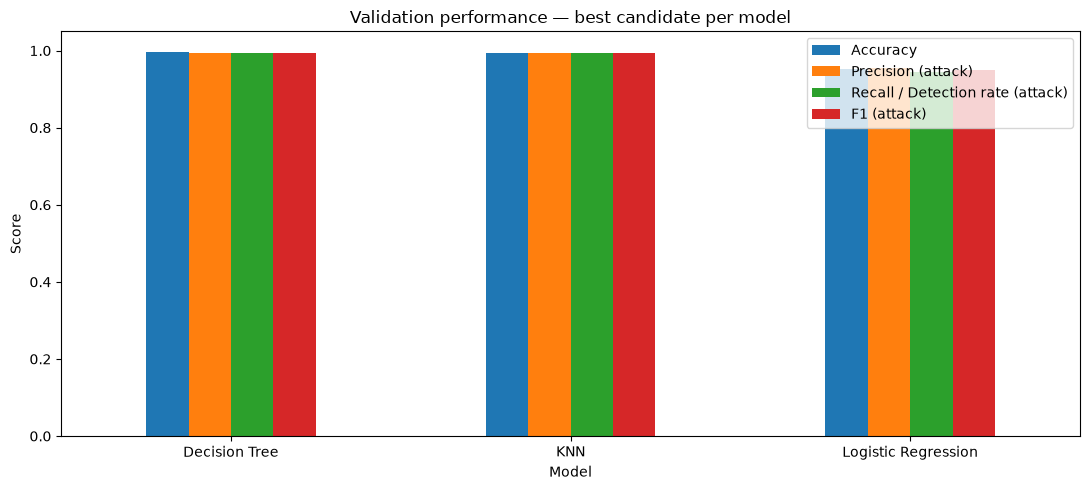

In [35]:
best_models = {
    "Logistic Regression": best_lr,
    "KNN": best_knn,
    "Decision Tree": best_dt,
}
validation_rows = []
for name, model in best_models.items():
    row, _ = evaluate_classifier(model, X_val_scaled, y_val, "Validation")
    row["Model"] = name
    validation_rows.append(row)

validation_results = pd.DataFrame(validation_rows).set_index("Model")
validation_results = validation_results.sort_values(
    ["F1 (attack)", "Recall / Detection rate (attack)"], ascending=False
)
display(validation_results.round(4))

best_model_name = validation_results.index[0]
print("Best model by validation F1 (attack):", best_model_name)

# Plot validation metrics
metrics_to_plot = ["Accuracy", "Precision (attack)", "Recall / Detection rate (attack)", "F1 (attack)"]
validation_results[metrics_to_plot].plot(kind="bar", figsize=(11, 5))
plt.title("Validation performance — best candidate per model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Final held-out test evaluation

The test set is used only now, after the validation comparison. We refit each selected model configuration on the combined train+validation data. To preserve the SMOTE approach, SMOTE is applied to the combined training data only; the test set remains untouched. The scaler is refitted on train+validation only.

In [36]:
X_trainval_final = pd.concat([X_train, X_val], axis=0)
y_trainval_final = pd.concat([y_train, y_val], axis=0)

imputer_final = SimpleImputer(strategy="median")
scaler_final = MinMaxScaler()
X_trainval_imp = imputer_final.fit_transform(X_trainval_final)
X_test_imp_final = imputer_final.transform(X_test)
X_trainval_scaled = scaler_final.fit_transform(X_trainval_imp)
X_test_scaled_final = scaler_final.transform(X_test_imp_final)

minority_final = int(y_trainval_final.value_counts().min())
if minority_final < 2:
    raise ValueError("Not enough minority-class training examples to apply SMOTE.")
smote_final = SMOTE(random_state=RANDOM_STATE, k_neighbors=min(5, minority_final - 1))
X_trainval_smote, y_trainval_smote = smote_final.fit_resample(X_trainval_scaled, y_trainval_final)

final_models = {
    "Logistic Regression": LogisticRegression(C=best_lr_C, max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=best_knn_params[0], weights=best_knn_params[1], n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, max_depth=best_dt_depth,
        min_samples_leaf=best_dt_params[1], class_weight=None
    ),
}

test_rows = []
test_predictions = {}
test_scores = {}
for name, model in final_models.items():
    t0 = time.perf_counter()
    model.fit(X_trainval_smote, y_trainval_smote)
    train_seconds = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(X_test_scaled_final)
    predict_seconds = time.perf_counter() - t0
    res, pred = evaluate_classifier(model, X_test_scaled_final, y_test, "Test")
    res.update({"Model": name, "Training time (s)": train_seconds,
                "Prediction time (s)": predict_seconds})
    test_rows.append(res)
    test_predictions[name] = pred
    if hasattr(model, "predict_proba"):
        try:
            test_scores[name] = model.predict_proba(X_test_scaled_final)[:, 1]
        except Exception:
            pass

test_results = pd.DataFrame(test_rows).set_index("Model").sort_values(
    ["F1 (attack)", "Recall / Detection rate (attack)"], ascending=False
)
display(test_results.round(4))
print("Reminder: test metrics are for final reporting only; do not tune on them.")

,Split,Accuracy,Precision (attack),Recall / Detection rate (attack),F1 (attack),Balanced accuracy,ROC-AUC,PR-AUC (average precision),Training time (s),Prediction time (s)
Model,,,,,,,,,,
Decision Tree,Test,0.9954,0.9949,0.9952,0.9951,0.9954,0.9957,0.9927,0.3961,0.0011
KNN,Test,0.9951,0.9944,0.9950,0.9947,0.9951,0.9982,0.9973,0.0049,1.1962
Logistic Regression,Test,0.9525,0.9569,0.9402,0.9485,0.9517,0.9880,0.9883,0.2007,0.0010


Reminder: test metrics are for final reporting only; do not tune on them.


## 13. Test confusion matrices and classification reports

\n========================================================================
Logistic Regression
              precision    recall  f1-score   support

      Normal       0.95      0.96      0.96     10101
      Attack       0.96      0.94      0.95      8795

    accuracy                           0.95     18896
   macro avg       0.95      0.95      0.95     18896
weighted avg       0.95      0.95      0.95     18896



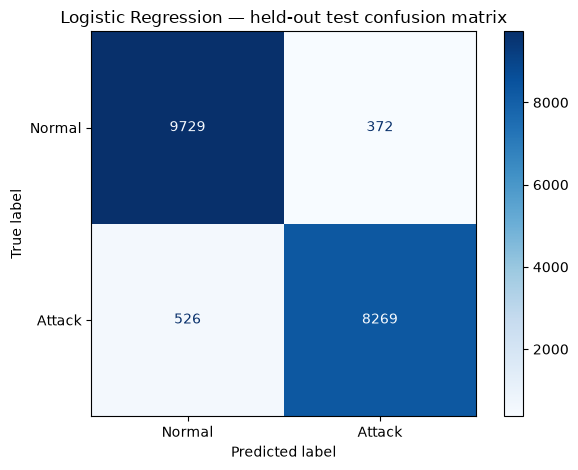

\n========================================================================
KNN
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     10101
      Attack       0.99      0.99      0.99      8795

    accuracy                           1.00     18896
   macro avg       1.00      1.00      1.00     18896
weighted avg       1.00      1.00      1.00     18896



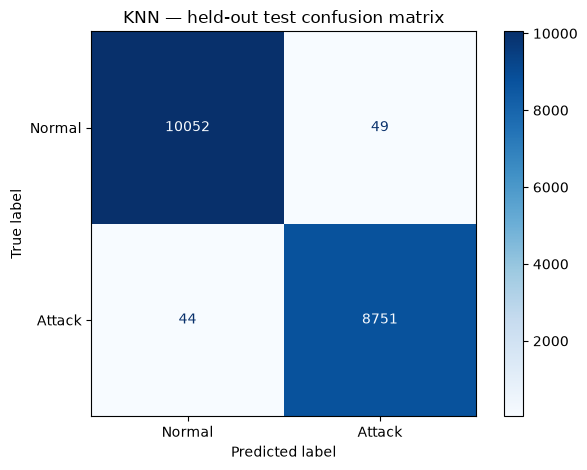

\n========================================================================
Decision Tree
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     10101
      Attack       0.99      1.00      1.00      8795

    accuracy                           1.00     18896
   macro avg       1.00      1.00      1.00     18896
weighted avg       1.00      1.00      1.00     18896



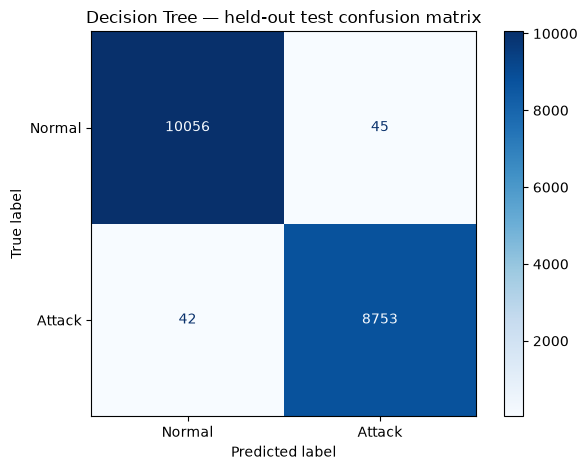

In [37]:
for name, pred in test_predictions.items():
    print("\\n" + "=" * 72)
    print(name)
    print(classification_report(y_test, pred, labels=[0, 1], target_names=["Normal", "Attack"], zero_division=0))
    plot_confusion(y_test, pred, f"{name} — held-out test confusion matrix")

## 14. ROC curves and precision–recall curves

These curves are shown for binary classification using the probability of the Attack class.

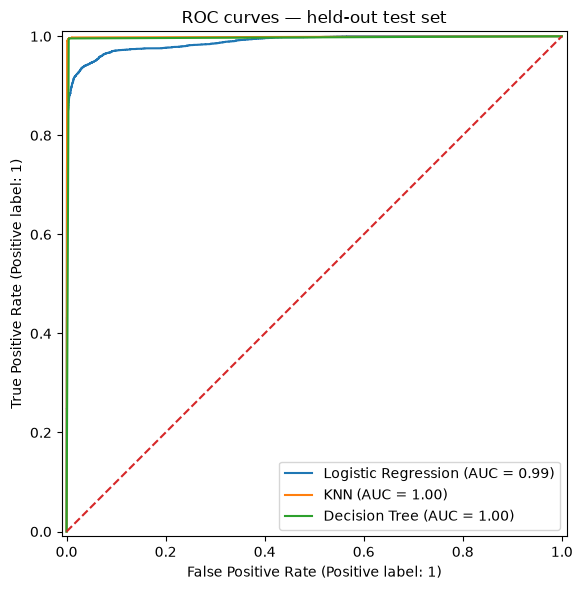

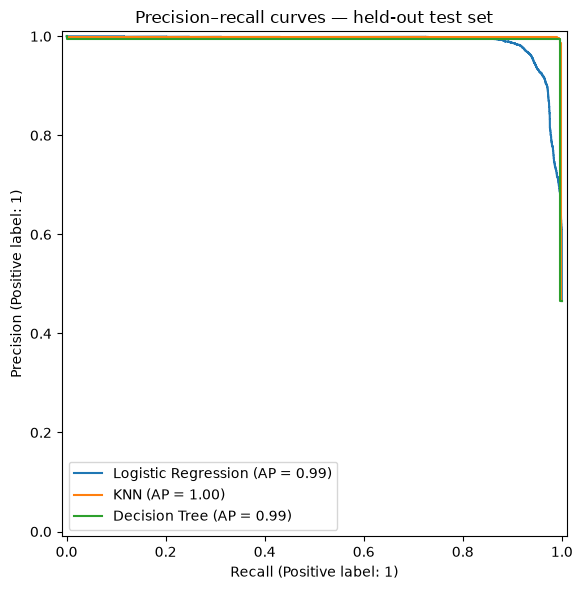

In [38]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in final_models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_scaled_final)[:, 1]
        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC curves — held-out test set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in final_models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_scaled_final)[:, 1]
        PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
ax.set_title("Precision–recall curves — held-out test set")
plt.tight_layout()
plt.show()

## 15. Decision Tree feature importance

Feature importance is calculated from the final Decision Tree. Because the earlier feature mapping and removal choices are preserved, these importances refer to the remaining numeric features.

,Importance
flag,0.56509
protocol_type,0.15668
dst_host_diff_srv_rate,0.08840
wrong_fragment,0.02627
hot,0.02229
count,0.01921
diff_srv_rate,0.01871
same_srv_rate,0.01572
duration,0.01450
dst_host_count,0.01406


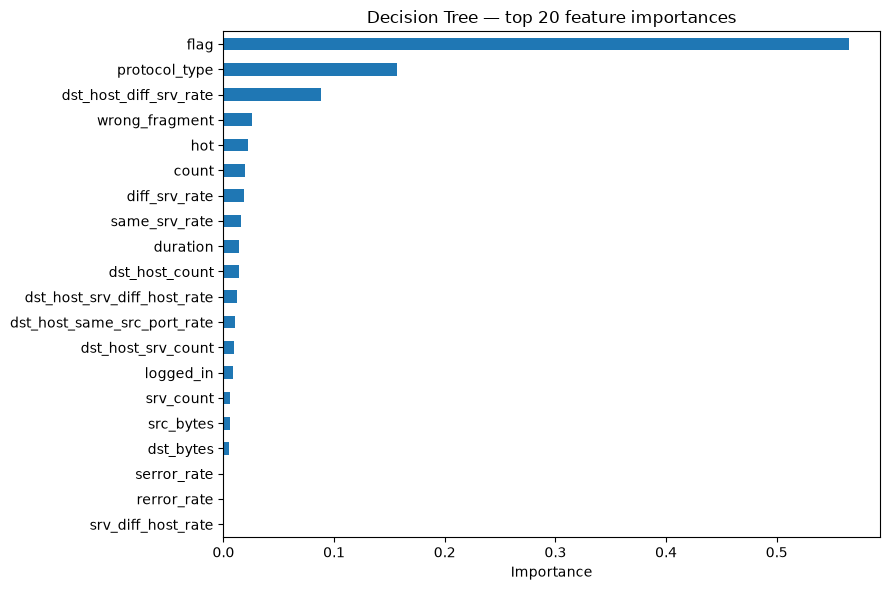

In [39]:
final_dt = final_models["Decision Tree"]
importance = pd.Series(final_dt.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importance.head(20).rename("Importance").to_frame().round(5))

plt.figure(figsize=(9, 6))
importance.head(20).sort_values().plot(kind="barh")
plt.title("Decision Tree — top 20 feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 16. Summary and reporting notes

- The target is binary: Normal = 0, Attack = 1.
- The requested model families are Logistic Regression, KNN, and Decision Tree.
- Existing feature-removal choices and protocol/flag mappings are retained.
- `service` remains dropped, as in the previous notebook.
- SMOTE remains part of the training workflow.
- The scaler is fit on training data only, and SMOTE never touches validation or test records.
- Validation metrics are used for model selection; final test metrics are reported separately.
- Accuracy should be interpreted alongside attack recall, precision, F1 and the confusion matrix. In an IDS, a high false-negative count means attacks are being missed.
- Results are not pre-filled: run the notebook with your `nsl_kdd.csv` file to generate the actual metrics.